<img src="https://drive.google.com/uc?export=view&id=1e7ctPi8O3bTQoLZaO9ZZjwGr2r8Z93RS" width="100%">

**Grupo 12**

David Martínez Triana · Andrés Ramírez Romero · David Delgado Ortiz

# Entendimiento y Preparación del Corpus
---

**Proyecto aplicado — Fase 2** (10% del proyecto)

Este notebook explora y prepara el corpus de la Fase 1. Cada bloque va en el mismo orden: el código y, debajo, la lectura de lo que imprimió.

- **Sección 1.** Cuántos pares hay, de dónde salen, qué tan largos son y qué relación hay entre pregunta y respuesta.
- **Sección 2.** Normalización, limpieza y lematización, con el corpus listo para la fase 3.

El archivo es `corpus_faq_unal.csv`: 839 pares de 22 páginas que sí se pudieron leer. Las direcciones que respondieron 404, 503 o un HTML sin preguntas no entran aquí.

- **Sección 3.** Un experimento de recuperación, con una consulta más corta que la pregunta oficial, para decidir qué texto conviene comparar en la fase 3.


### **Dónde queda esta fase**

```mermaid
flowchart LR
  CSV["CSV de la Fase 1<br/>839 pares"] --> E["1. Exploración"]
  E --> L["2. Limpieza"]
  L --> OUT["CSV limpio<br/>+ columnas normalizadas"]
  OUT --> F3["Fase 3"]
```

La exploración describe el corpus. La limpieza no pisa el texto original: agrega `pregunta_normalizada` y `pregunta_texto_limpio`.


In [1]:
from pathlib import Path
import shutil

import pandas as pd

# Corpus armado en la Fase 1. En Colab hay que subir corpus_faq_unal.csv
# al directorio de trabajo antes de ejecutar esta celda.
origenes = [
    Path("corpus_faq_unal.csv"),
    Path("../Fase I/corpus_faq_unal.csv"),
]
for origen in origenes:
    if origen.exists():
        destino = Path("corpus_faq_unal.csv")
        if origen.resolve() != destino.resolve():
            shutil.copyfile(origen, destino)
        print("Corpus de la Fase 1:", origen.resolve())
        break
else:
    raise FileNotFoundError(
        "No está corpus_faq_unal.csv. Súbalo: es el archivo que guarda la Fase 1."
    )


Corpus de la Fase 1: C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 4\Módulo 4\Entrega proyecto Fase II\corpus_faq_unal.csv


**Explicación.** La celda busca `corpus_faq_unal.csv` en esta carpeta y, si no está, lo copia desde `Fase I`. En Colab hay que subir el archivo al directorio de trabajo. Si ninguna de las dos rutas existe, el notebook se detiene: la fase 2 no arma un corpus distinto al de la fase 1.


In [2]:
import spacy
import pandas as pd
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from collections import Counter

**Explicación.** Esta celda solo importa las librerías. `pandas` sostiene la tabla, `spaCy` parte y lematiza en español, y `matplotlib` con `seaborn` dibujan las distribuciones. No leen el archivo ni cambian datos.


In [3]:
def cargar_corpus(ruta="corpus_faq_unal.csv"):
    """Carga el corpus de la Fase 1. No usa archivos de corridas anteriores."""
    path = Path(ruta)
    if not path.exists():
        raise FileNotFoundError(
            "No está corpus_faq_unal.csv. Ejecute antes la celda que lo trae de la Fase 1."
        )
    df = pd.read_csv(path, encoding="utf-8")
    df = df.dropna(subset=["pregunta", "respuesta"])
    df = df[
        (df["pregunta"].astype(str).str.strip() != "")
        & (df["respuesta"].astype(str).str.strip() != "")
    ]
    if "titulo_seccion" not in df.columns:
        df["titulo_seccion"] = ""
    df["titulo_seccion"] = df["titulo_seccion"].fillna("").astype(str).str.strip().replace({"nan": ""})
    if "fuente" not in df.columns:
        df["fuente"] = ""
    if "url" not in df.columns:
        df["url"] = ""
    print(f"Corpus cargado desde: {ruta} | Filas: {len(df)} | Fuentes: {df['fuente'].nunique()}")
    return df.reset_index(drop=True)


In [4]:
try:
    nlp = spacy.load("es_core_news_sm")
    print("Modelo es_core_news_sm ya estaba instalado.")
except OSError:
    spacy.cli.download("es_core_news_sm")
    nlp = spacy.load("es_core_news_sm")
nlp.max_length = 3_000_000
df = cargar_corpus()


Modelo es_core_news_sm ya estaba instalado.
Corpus cargado desde: corpus_faq_unal.csv | Filas: 839 | Fuentes: 22


**Explicación.** Si el modelo `es_core_news_sm` ya está en el entorno, se carga y no se vuelve a descargar. `cargar_corpus` lee `corpus_faq_unal.csv`, descarta una fila solo si la pregunta o la respuesta vinieran vacías y deja `titulo_seccion` en blanco cuando la página no trae sección.

La salida de esta ejecución es **839 filas** y **22 fuentes**. Ese es el corpus de todo el notebook.


### **Funciones sección 1.1 - 1.2**

In [5]:
def resumen_general(df):
    """Resume tamaño, fuentes y secciones reales. Un vacío no cuenta como sección."""
    n_docs = len(df)
    tamano_mb = round(df.memory_usage(deep=True).sum() / (1024 * 1024), 4)
    seccion = df["titulo_seccion"].fillna("").astype(str).str.strip().replace({"nan": ""})
    con_seccion = seccion[seccion != ""]
    titulos = con_seccion.unique()
    fuentes = df["fuente"].nunique() if "fuente" in df.columns else 0
    return (
        f"Existen {n_docs} pares de pregunta-respuesta\n"
        f"El tamaño del DataFrame es de {tamano_mb} MB\n"
        f"Fuentes: {fuentes}\n"
        f"Filas con título de sección: {len(con_seccion)}. Secciones distintas: {len(titulos)}\n"
        f"{titulos}"
    )


In [6]:
def documentos_vacios(df, traer_df_nan=False):
    """Cuenta celdas vacías. Un título de sección en blanco no es un NaN de pandas."""
    def es_vacio(serie):
        texto = serie.fillna("").astype(str).str.strip()
        return texto.eq("") | texto.str.lower().eq("nan")

    por_columna = {col: int(es_vacio(df[col]).sum()) for col in df.columns}
    sin_seccion = por_columna.get("titulo_seccion", 0)
    metrics = {
        "celdas_vacias_por_columna": por_columna,
        "filas_sin_titulo_de_seccion": sin_seccion,
        "filas_con_titulo_de_seccion": int(len(df) - sin_seccion),
    }
    if traer_df_nan:
        metrics["filas_sin_seccion"] = df.loc[es_vacio(df["titulo_seccion"])]
    return metrics


In [7]:
def metricas_de_doc(doc):
    """Cuenta tokens con un carácter fuera del español básico."""
    metrics = {
        "tokens_totales": len(doc),
        "mal_codificados": 0,
        "ejemplos_basura": [],
    }
    for token in doc:
        if re.search(r"[^\x00-\x7FáéíóúÁÉÍÓÚñÑüÜ\s\.,;!¿?]", token.text):
            metrics["mal_codificados"] += 1
            metrics["ejemplos_basura"].append(token.text)
    return metrics

def aplicar_analisis_ruido(df, columnas):
    """Recorre cada columna en lote con nlp.pipe, no fila por fila."""
    df_resultado = pd.DataFrame(index=df.index)
    for col in columnas:
        textos = df[col].fillna("").astype(str).tolist()
        filas = [metricas_de_doc(doc) for doc in nlp.pipe(textos, batch_size=64)]
        df_metricas = pd.DataFrame(filas, index=df.index)
        df_metricas.columns = [f"{col}_{nombre}" for nombre in df_metricas.columns]
        df_resultado = pd.concat([df_resultado, df_metricas], axis=1)
    return df_resultado


In [8]:
def graficar_frecuencias_error(df):
    """Dibuja el conteo. El nombre de la columna no se muestra: no son textos mal codificados."""
    columnas_error = [c for c in df.columns if "mal_codificados" in c]
    frecuencias = df[columnas_error].sum().sort_values(ascending=False)
    etiquetas = [
        nombre.replace("_mal_codificados", "").replace("_", " ")
        for nombre in frecuencias.index
    ]

    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")
    ax = sns.barplot(x=frecuencias.values, y=etiquetas, palette="magma")
    for i, valor in enumerate(frecuencias.values):
        ax.text(valor + 0.5, i, f"{int(valor)}", color="black", va="center", fontweight="bold")
    plt.title("Caracteres fuera del español básico", fontsize=14)
    plt.xlabel("Número total de apariciones", fontsize=12)
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


In [9]:
def traer_ejemplos_basura(df, columnas):
  df_result = pd.DataFrame()
  for col in columnas:
    df_col = df[df[f"{col}_mal_codificados"].gt(0)][f"{col}_ejemplos_basura"]
    df_result = pd.concat([df_result,df_col],axis=1)

  return df_result

**Explicación.** Estas funciones solo quedan definidas. `resumen_general` cuenta pares, peso, fuentes y secciones con título. `documentos_vacios` distingue una celda vacía de un título de sección en blanco. `metricas_de_doc` marca tokens con caracteres fuera del español básico. `aplicar_analisis_ruido` los cuenta en lote, con `nlp.pipe`. Las dos últimas arman la gráfica y la lista de ejemplos. Ninguna modifica `df`.


### **Funciones sección 1.3**

In [10]:
def frecuencia_palabras(df, columnas):
    """Lemas sin stopwords, ordenados de mayor a menor frecuencia."""
    df_frecuencia_palabras = {}
    for col in columnas:
        text = " ".join(df[col].astype(str).tolist())
        corpus = nlp(text)
        lemmas = [
            token.lemma_.lower()
            for token in corpus
            if not token.is_stop and not token.is_punct and not token.is_space and token.lemma_.strip()
        ]
        frecuencia_tokens = Counter(lemmas)
        df_frecuencia_tokens = (
            pd.Series(frecuencia_tokens)
            .to_frame()
            .reset_index()
            .rename(columns={"index": "palabra", 0: "frecuencia"})
            .sort_values("frecuencia", ascending=False)
            .reset_index(drop=True)
        )
        df_frecuencia_palabras[col] = df_frecuencia_tokens
    return df_frecuencia_palabras


In [11]:
def freqRatio(df):
  ratio = len(df)/sum(df["frecuencia"])
  return ratio

In [12]:
def longitud_de_doc(df, columnas):
  df_distribucion = pd.DataFrame()
  for col in columnas:
    df_distribucion[f"Longitud_{col}"] = df[f"{col}"].astype(str).apply(lambda x: len(x.split()))
  return df_distribucion


In [13]:
def graficar_distribucion_palabras(df):
  plt.figure(figsize=(10, 6))
  sns.histplot(df, kde=True, color="skyblue", bins=30)
  plt.title("Distribución del número de palabras por pregunta")
  plt.xlabel("Número de Tokens (Palabras)")
  plt.ylabel("Frecuencia (Número de preguntas)")
  plt.show()

**Explicación.** Estas cuatro funciones todavía no recorren el corpus. `frecuencia_palabras` lematiza y ordena. `freqRatio` divide las palabras distintas entre el total de apariciones. `longitud_de_doc` cuenta palabras separadas por espacio. `graficar_distribucion_palabras` dibuja el histograma de la pregunta. Los números salen cuando se llaman, más abajo.


### **Mapa de la exploración**

```mermaid
flowchart TD
  R["1.1 Resumen<br/>tamaño, fuentes, idioma"] --> Q["1.2 Calidad<br/>vacíos, tipografía, ruido"]
  Q --> T["1.3 Tipos<br/>longitudes, forma de la pregunta"]
  T --> V["1.4 Relaciones<br/>repetidas, Jaccard, desbalance"]
  V --> H["Hallazgos"]
  H --> L["2. Limpieza"]
```


## **1. Análisis Exploratorio de los Textos**
---


### **1.1. Resumen General de los Textos**
---


### **¿Cuántos documentos tiene el corpus? ¿En qué idioma están? ¿Cuánto pesa? ¿Hay relación entre documentos?**

La celda siguiente imprime el número de pares, el peso del DataFrame, las fuentes y las secciones que sí traen título. La lectura está debajo de esa salida.


In [14]:
print(resumen_general(df))

Existen 839 pares de pregunta-respuesta
El tamaño del DataFrame es de 0.8333 MB
Fuentes: 22
Filas con título de sección: 252. Secciones distintas: 36
['Glosario' 'Adquisición de material bibliográfico' 'Agenda cultural'
 'Biblioteca digital UN' 'Recursos electrónicos' 'Depósito legal'
 'Donaciones' 'Egresados' 'Formación' 'Horario de bibliotecas' 'Multas'
 'Obtención de documentos' 'Paz y salvos' 'Peticiones, quejas y reclamos'
 'Portal de revistas' 'Préstamo externo' 'Préstamo interbibliotecario'
 'Recursos bibliográficos' 'Referencia' 'Repositorio Institucional'
 'Usuarios Externos' 'Usuarios internos'
 'Corrección de estilo de textos en inglés y español' 'Convenios'
 'Jóvenes Investigadores e Innovadores' 'Convocatorias externas'
 'Movilidades' 'Convocatorias internas'
 'Proyectos de Investigación Externos' 'Proyectos internos'
 'Preguntas frecuentes para aspirantes'
 'Preguntas Frecuentes Estudiantes Activos Pregrado'
 'Preguntas sobre la Especialización en Estadística'
 'Preguntas

**Explicación.** El corpus tiene **839 pares**. El DataFrame ocupa **0.83 MB**; el CSV en disco pesa cerca de **0.55 MB**. Sigue siendo un corpus pequeño para un equipo local.

Hay **22 fuentes**. Todas las páginas están en español. En medio del español aparecen siglas, nombres de sistemas y URL; no hay un segundo idioma que haya que separar.

**252** filas traen título de sección y hay **36** secciones distintas. Salen de tres sitios que sí agrupan: Bibliotecas (adquisición, préstamo, multas, repositorio), Ingeniería Bogotá (convenios, movilidades, proyectos, convocatorias) y Estadística (aspirantes, pregrado, especialización, maestría, doctorado y posgrados), más el `Glosario` de la UECP. El resto de las filas deja la sección en blanco porque su página no la publica.

Los documentos se relacionan por el tipo de trámite, no porque sean el mismo texto. `fuente` y `url` separan una respuesta de biblioteca de una de Hermes aunque las dos hablen de una solicitud.


### **1.2. Resumen de la Calidad de los Textos**
---

- ¿Hay datos faltantes o documentos vacíos?
- ¿Hay documentos ilegibles o con problemas de codificación?
- ¿Hay mezcla de idiomas? ¿Qué se hace al respecto?


### **Datos faltantes o documentos vacíos**

La celda siguiente cuenta celdas vacías por columna. Una sección en blanco no es lo mismo que una pregunta o una respuesta vacía.


In [15]:
display(documentos_vacios(df,False))

{'celdas_vacias_por_columna': {'pregunta': 0,
  'respuesta': 0,
  'fuente': 0,
  'url': 0,
  'titulo_seccion': 587},
 'filas_sin_titulo_de_seccion': 587,
 'filas_con_titulo_de_seccion': 252}

**Explicación.** `pregunta`, `respuesta`, `fuente` y `url` tienen **0** celdas vacías: los 839 pares están completos.

`titulo_seccion` está vacío en **587** filas y trae texto en **252**. El vacío es el caso en que la página no publica un grupo, como Hermes, DAMA, SIAPAL, personal y la mayoría de facultades. Las 252 filas con sección salen de Bibliotecas, Estadística, el glosario de la UECP y una parte de Ingeniería Bogotá. La columna se conserva: cuando tiene texto, dice el tema del par.


### **Documentos ilegibles o con problemas de codificación**



La celda siguiente aplica el detector a `pregunta`, `respuesta` y `titulo_seccion`. Cada fila del resultado corresponde al mismo par del corpus.


In [16]:
df_analisis_ruido = aplicar_analisis_ruido(df,["pregunta","respuesta","titulo_seccion"])
display(df_analisis_ruido)

,pregunta_tokens_totales,pregunta_mal_codificados,pregunta_ejemplos_basura,respuesta_tokens_totales,respuesta_mal_codificados,respuesta_ejemplos_basura,titulo_seccion_tokens_totales,titulo_seccion_mal_codificados,titulo_seccion_ejemplos_basura
0,15,0,[],36,0,[],0,0,[]
1,13,0,[],60,0,[],0,0,[]
2,18,0,[],47,0,[],0,0,[]
3,9,0,[],66,0,[],0,0,[]
4,26,0,[],82,0,[],0,0,[]
...,...,...,...,...,...,...,...,...,...
834,22,0,[],62,0,[],0,0,[]
835,17,0,[],35,0,[],0,0,[]
836,7,0,[],110,0,[],0,0,[]
837,10,0,[],74,0,[],0,0,[]


**Explicación.** Hay una fila de esta tabla por cada par del corpus. Las columnas `tokens_totales` cuentan lo que spaCy partió. Las columnas `mal_codificados` cuentan tokens con un carácter fuera del español básico, y `ejemplos_basura` guarda esos tokens. La mayoría de las filas tiene cero en `mal_codificados`. Donde el número es mayor que cero, el ejemplo suele ser una comilla curva, una raya o una viñeta, no una palabra ilegible.


Con estos resultados vamos a graficar lo encontrado:

C:\Users\J2KUSER\AppData\Local\Temp\ipykernel_32228\3511458649.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=frecuencias.values, y=etiquetas, palette="magma")


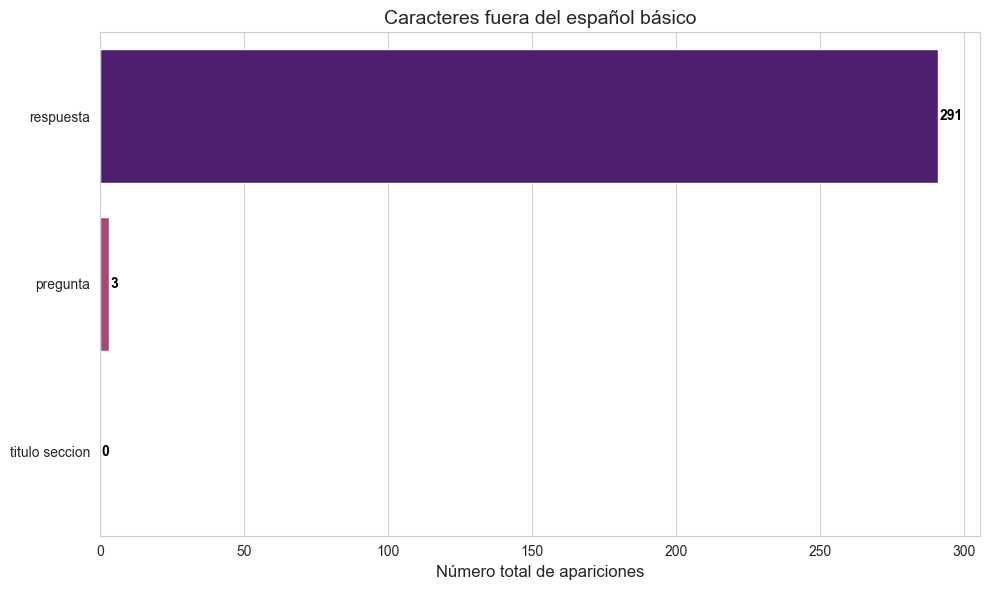

In [17]:
graficar_frecuencias_error(df_analisis_ruido)

**Explicación.** Cada barra suma los tokens que el detector marcó en esa columna. La barra de la respuesta es la alta: ahí están las comillas curvas, las rayas, los puntos suspensivos y las viñetas. La pregunta y el título de sección aportan muy poco. El número de la barra no es una fila dañada: es un carácter suelto dentro de un texto que sí se lee.


In [18]:
df_ejemplos_basura = traer_ejemplos_basura(df_analisis_ruido,["respuesta", "pregunta","titulo_seccion"])
display(df_ejemplos_basura)


,respuesta_ejemplos_basura,pregunta_ejemplos_basura,titulo_seccion_ejemplos_basura
244,"[“, ”]",NaN,NaN
299,"[1.ª., 2.ª, 3.ª., 4.ª, 5.ª]",NaN,NaN
318,"[“, ”]",NaN,NaN
319,"[“, ”]",NaN,NaN
360,"[2º, 3º.]",NaN,NaN
...,...,...,...
826,"[“, ”, –, “, ”, “, ”, “, ”]",NaN,NaN
833,"[•, •, •]",NaN,NaN
476,NaN,[​¿Qué],NaN
800,NaN,[–],NaN


**Explicación.** El detector marca cualquier carácter fuera de un conjunto estrecho del español. En este corpus eso es, sobre todo, tipografía de las páginas:

- comillas curvas (`“` `”`), raya y guion largo, puntos suspensivos y viñetas;
- ordinales (`º`, `ª`, `°`);
- un espacio de ancho cero y una `Ì`.

Las respuestas concentran esas marcas porque son el texto largo. Las preguntas y los títulos de sección casi no las traen. La limpieza de la sección 2 unifica comillas, rayas y viñetas. El signo `°` de un ordinal, como en `2°`, se conserva.


### **Mezcla de idiomas**

Los documentos están en español: salen de páginas de la Universidad. Aparecen siglas, nombres de sistemas y URL en inglés (`click`, `Hermes`, enlaces). No hay un segundo corpus en otro idioma que haya que separar antes de tokenizar.

### **1.3. Tipos de variables**
---

- ¿El corpus tiene una variable objetivo a estimar? ¿Es continua o categórica?
- ¿Hay desbalance en esa variable?
- ¿Cómo se distribuye la longitud de los documentos, en palabras y en caracteres?
- ¿Qué otras variables hay y cuáles entran al modelo?


### **Variable objetivo**

En esta fase no hay una etiqueta por fila: todavía no se evalúa una pregunta nueva. Lo que la fase 4 va a recuperar es **un par del corpus**, es decir, el índice de la fila cuya pregunta se parece más a la consulta.

Por eso las variables se leen así:

- `pregunta` y `respuesta` son texto. Son las que se comparan.
- `fuente`, `url` y `titulo_seccion` son categóricas. Dicen de qué página salió el par y no se predicen.


### **Forma de la pregunta**

No hay una etiqueta de clase. La forma interrogativa es una descripción de la pregunta, no la variable que se predice. La celda toma la primera palabra interrogativa, con tilde o sin ella.


pregunta
cómo         221
qué          199
cuál         134
otra          87
sí o no       67
dónde         41
sin signo     25
quién         24
cuándo        21
cuánto        20
Name: count, dtype: int64


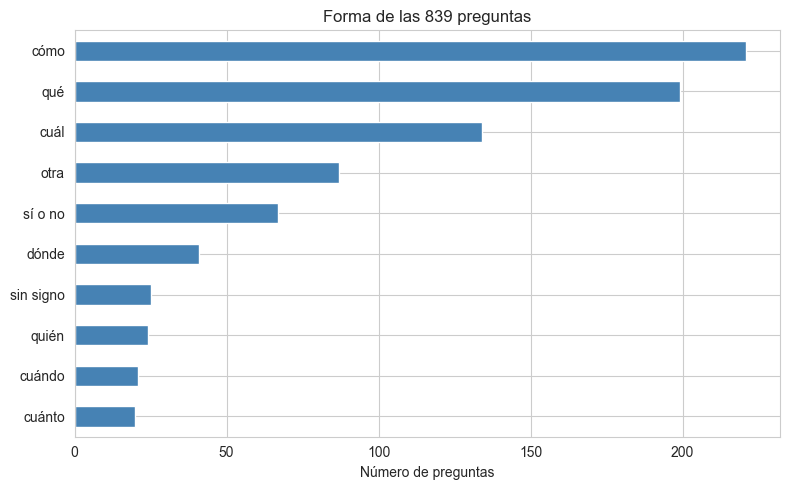

In [19]:
import re

def sin_tilde(texto):
    return str(texto).casefold().translate(str.maketrans("áéíóúü", "aeiouu"))

def tipo_pregunta(pregunta):
    """Usa la primera palabra interrogativa, no un recorte dentro de otra palabra."""
    texto = sin_tilde(pregunta)
    patrones = [
        ("cuánto", r"\bcuant[oa]s?\b"),
        ("cuándo", r"\bcuando\b"),
        ("dónde", r"\bdonde\b"),
        ("quién", r"\bquien(?:es)?\b"),
        ("cómo", r"\bcomo\b"),
        ("cuál", r"\bcual(?:es)?\b"),
        ("qué", r"\bque\b"),
    ]
    hallazgos = []
    for nombre, patron in patrones:
        coincidencia = re.search(patron, texto)
        if coincidencia:
            hallazgos.append((coincidencia.start(), nombre))
    if hallazgos:
        return min(hallazgos)[1]
    if not re.search(r"[¿?]", str(pregunta)):
        return "sin signo"
    if re.search(r"\b(?:se puede|es posible|puedo|debo|hay)\b", texto):
        return "sí o no"
    return "otra"

conteo_tipos = df["pregunta"].map(tipo_pregunta).value_counts()
print(conteo_tipos)
plt.figure(figsize=(8, 5))
conteo_tipos.sort_values().plot(kind="barh", color="steelblue")
plt.title("Forma de las 839 preguntas")
plt.xlabel("Número de preguntas")
plt.ylabel("")
plt.tight_layout()
plt.show()


**Explicación.** La etiqueta es la primera palabra interrogativa de la pregunta, con o sin tilde. `que` suelto dentro de otra palabra no cuenta.

La forma más frecuente es **cómo** (221), seguida de **qué** (199) y **cuál** (134). Entre las tres suman 554 preguntas. Siguen **dónde** (41), **quién** (24), **cuándo** (21) y **cuánto** (20).

**67** preguntas son de sí o no (`se puede`, `es posible`, `puedo`, `debo`, `hay`). **87** no usan ninguna de esas fórmulas: son del tipo «¿soy estudiante y quiero…?» o «¿un semillero puede ser coordinado…?». **25** no traen palabra interrogativa ni signo; ahí están los términos del glosario.

No hace falta un clasificador de intenciones para este proyecto. Las formas se mezclan dentro de la misma página y la tarea sigue siendo recuperar el par, no ponerle una etiqueta a la pregunta.


### **Análisis de distribución**

#### **1. Análisis de distribución de palabras**

La celda siguiente lematiza pregunta, respuesta y título de sección, quita stopwords y puntuación, y ordena cada tabla de mayor a menor frecuencia.


In [20]:

diccionarios_frecuencia_palabras = frecuencia_palabras(df,["pregunta","respuesta","titulo_seccion"])


In [21]:
display (diccionarios_frecuencia_palabras["pregunta"],diccionarios_frecuencia_palabras["respuesta"],diccionarios_frecuencia_palabras["titulo_seccion"])

,palabra,frecuencia
0,solicitar,71
1,proyecto,49
2,semillero,47
3,solicitud,45
4,universidad,44
...,...,...
1051,contratista,1
1052,destinatario,1
1053,estatuto,1
1054,171,1


,palabra,frecuencia
0,académico,394
1,estudiante,289
2,consejo,287
3,información,271
4,solicitud,267
...,...,...
3808,limitar,1
3809,intervención,1
3810,gravedad,1
3811,juramento,1


,palabra,frecuencia
0,preguntas,102
1,estadística,60
2,estudiantes,58
3,posgrados,30
4,frecuentes,28
...,...,...
59,material,1
60,depósitir,1
61,depósito,1
62,donaciones,1


**Explicación.** La primera tabla es la pregunta, la segunda la respuesta y la tercera el título de sección. Están ordenadas por frecuencia.

En la pregunta pesan trámites e investigación: *solicitar* (71), *proyecto* (49), *semillero* (47), *solicitud* (45), *universidad* (44), *académico* (43), *estudiante* (40). En la respuesta el vocabulario se abre: *académico* (394), *estudiante* (289), *consejo* (287), *información* (271), *facultad* (267). Esa diferencia importa en la fase 3: la pregunta es corta y repetida; la respuesta es larga y más variada.

La celda siguiente convierte esas tablas en el porcentaje de palabras únicas sobre el total de palabras.


In [22]:
display(freqRatio(diccionarios_frecuencia_palabras["pregunta"])*100,
freqRatio(diccionarios_frecuencia_palabras["respuesta"])*100,
freqRatio(diccionarios_frecuencia_palabras["titulo_seccion"])*100)

24.62112380508277

12.785005364806867

8.98876404494382

El porcentaje de palabras únicas sobre el total de palabras es:

- **Pregunta:** 24.6%
- **Respuesta:** 12.8%
- **Título de sección:** 9.0%

La pregunta repite menos el vocabulario que la respuesta. En la fase 3 conviene una representación que no se quede solo con las palabras más frecuentes del párrafo largo.

#### **Longitud de la pregunta y de la respuesta**

La pregunta es el texto con el que se va a comparar la consulta del usuario. La respuesta es el texto que se devuelve. Las dos celdas siguientes miden la pregunta; la que va después mide la respuesta.


In [23]:
display(longitud_de_doc(df,["pregunta"]), longitud_de_doc(df,["pregunta"]).describe())

,Longitud_pregunta
0,13
1,11
2,16
3,7
4,23
...,...
834,18
835,13
836,5
837,8


,Longitud_pregunta
count,839.000000
mean,11.702026
std,5.968844
min,1.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,41.000000


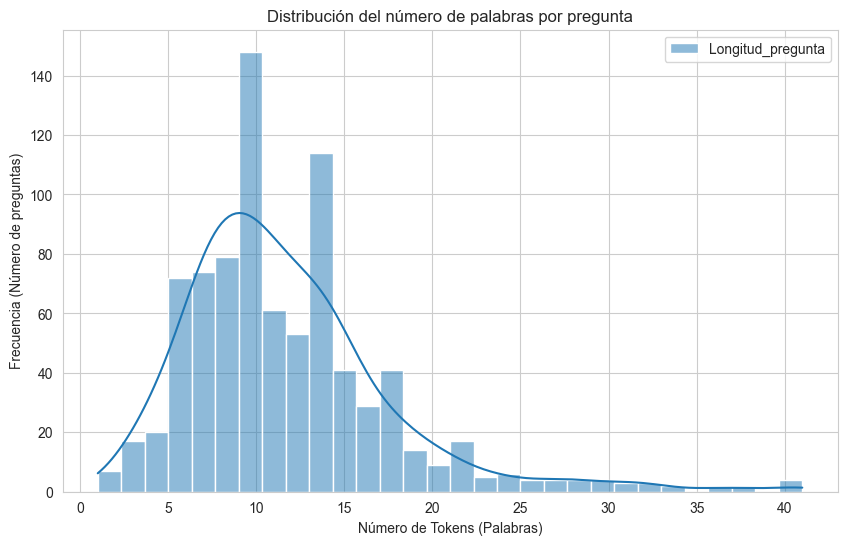

In [24]:
graficar_distribucion_palabras(longitud_de_doc(df,["pregunta"]))

**Explicación.** La tabla y el histograma son la longitud de la **pregunta**, en palabras.

1. La media es 11.7 palabras y la desviación estándar es 6.0.
2. La mediana es 11: la mitad de las preguntas tiene 11 palabras o menos.
3. La más corta tiene 1 palabra (un término del glosario) y la más larga tiene 41.
4. El histograma tiene dos picos: uno en 8 a 10 palabras (227 preguntas) y otro en 13 a 14 (114). La curva suavizada tapa el valle que hay entre los dos. A la derecha, entre 36 y 41 palabras, solo quedan ocho filas: varias son la misma pregunta de personal en dos páginas, y otras traen dos preguntas en la misma celda.

La pregunta del usuario, cuando llegue la fase 4, va a tener un tamaño parecido al de esta columna.


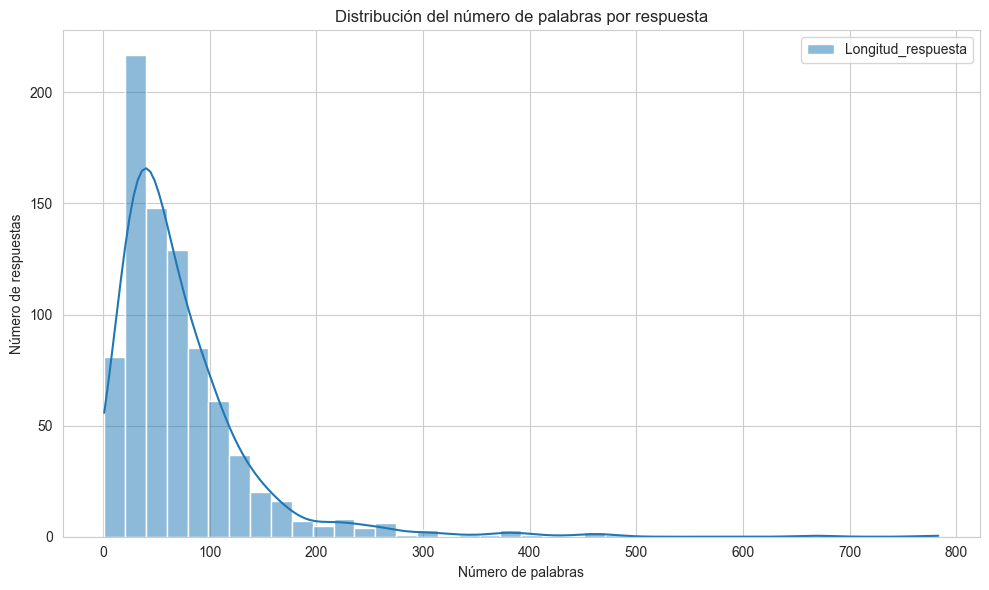

,Longitud_respuesta
count,839.000000
mean,72.876043
std,69.325708
min,1.000000
25%,32.000000
50%,54.000000
75%,91.500000
max,783.000000


In [25]:
longitud_respuesta = longitud_de_doc(df, ["respuesta"])
plt.figure(figsize=(10, 6))
sns.histplot(longitud_respuesta, kde=True, color="steelblue", bins=40)
plt.title("Distribución del número de palabras por respuesta")
plt.xlabel("Número de palabras")
plt.ylabel("Número de respuestas")
plt.tight_layout()
plt.show()
longitud_respuesta.describe()


**Explicación de la longitud de la respuesta.** La media es **72.9** palabras, la mediana es **54** y la desviación estándar es **69.3**. El máximo llega a **783** palabras y el eje lo incluye. Casi toda la masa está por debajo de 150; la cola es delgada y por eso la media queda por encima de la mediana.

La fase 4 compara la consulta con la pregunta, que ronda 12 palabras, y devuelve esta respuesta, que suele ser varias veces más larga.


In [26]:
longitud_caracteres = pd.DataFrame({
    "caracteres_pregunta": df["pregunta"].astype(str).str.len(),
    "caracteres_respuesta": df["respuesta"].astype(str).str.len(),
    "palabras_pregunta": df["pregunta"].astype(str).str.split().str.len(),
    "palabras_respuesta": df["respuesta"].astype(str).str.split().str.len(),
})
display(longitud_caracteres[["caracteres_pregunta", "caracteres_respuesta"]].describe().round(1))
correlacion_pregunta = longitud_caracteres["caracteres_pregunta"].corr(longitud_caracteres["palabras_pregunta"])
correlacion_respuesta = longitud_caracteres["caracteres_respuesta"].corr(longitud_caracteres["palabras_respuesta"])
print(f"Correlación caracteres-palabras en la pregunta: {correlacion_pregunta:.3f}")
print(f"Correlación caracteres-palabras en la respuesta: {correlacion_respuesta:.3f}")


,caracteres_pregunta,caracteres_respuesta
count,839.0,839.0
mean,74.0,477.9
std,36.8,451.0
min,9.0,22.0
25%,50.0,214.0
50%,68.0,362.0
75%,90.0,598.5
max,262.0,5154.0


Correlación caracteres-palabras en la pregunta: 0.975
Correlación caracteres-palabras en la respuesta: 0.994


**Explicación.** En caracteres, la pregunta tiene media **74** y mediana **68** (mínimo 9, máximo 262). La respuesta tiene media **478** y mediana **362** (mínimo 22, máximo 5154).

La longitud en caracteres y la longitud en palabras van juntas: la correlación es **0.975** en la pregunta y **0.994** en la respuesta. Medir las dos es redundante. En adelante se usa el número de palabras.


### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

La celda siguiente cuenta los pares de cada fuente y la correlación entre el número de palabras de la pregunta y el de la respuesta.


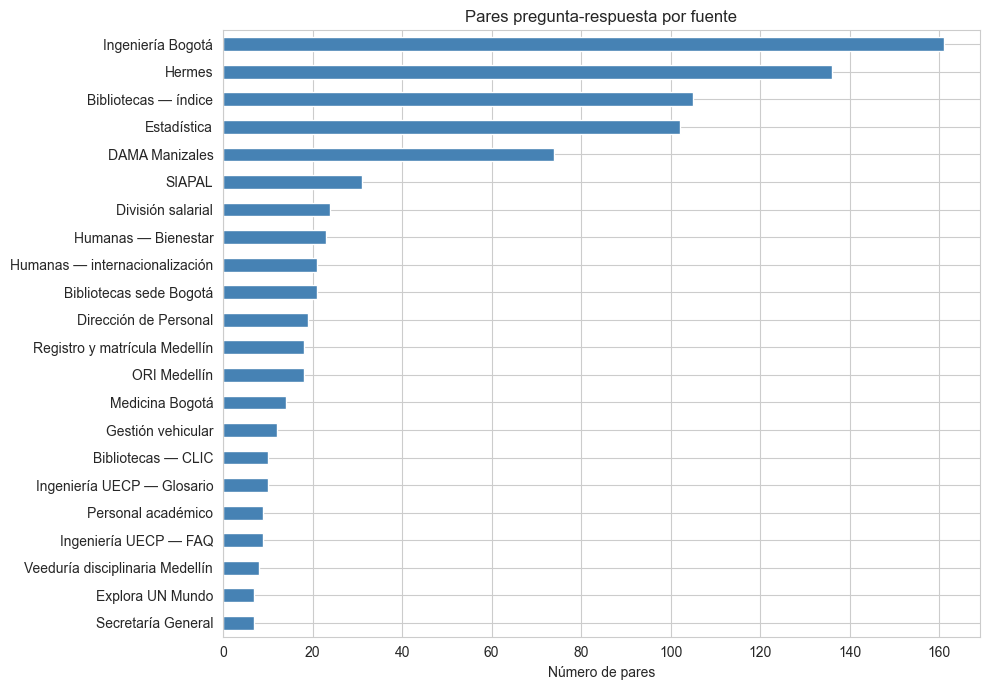

Correlación entre palabras de la pregunta y de la respuesta: -0.02


In [27]:
import matplotlib.pyplot as plt

conteo = df["fuente"].value_counts().sort_values(ascending=True)
plt.figure(figsize=(10, 7))
conteo.plot(kind="barh", color="steelblue")
plt.title("Pares pregunta-respuesta por fuente")
plt.xlabel("Número de pares")
plt.ylabel("")
plt.tight_layout()
plt.show()

relacion = pd.DataFrame({
    "palabras_pregunta": df["pregunta"].astype(str).str.split().str.len(),
    "palabras_respuesta": df["respuesta"].astype(str).str.split().str.len(),
})
correlacion = relacion.corr().iloc[0, 1]
print(f"Correlación entre palabras de la pregunta y de la respuesta: {correlacion:.2f}")


**Explicación.** Cada barra es una fuente y el largo es el número de pares. Ingeniería Bogotá, Hermes, Bibliotecas, Estadística y DAMA Manizales quedan arriba. Las otras 17 fuentes quedan por debajo de 35 pares. Ese desbalance es el dato que la fase 4 tiene que tener en cuenta: las páginas grandes pueden dominar la recuperación si no se mira la fuente.

La correlación impresa es **-0.02**. Una pregunta corta puede tener una respuesta muy larga, y al revés. No hay una columna de longitud que se pueda borrar por redundante. `pregunta` y `respuesta` cumplen papeles distintos, y `fuente`, `url` y `titulo_seccion` se quedan porque dicen de dónde salió el par.


### **Preguntas repetidas y solapamiento**

La celda siguiente mide cuatro cosas que el promedio del corpus no muestra: cuánto pesan las fuentes grandes, si la misma pregunta está en dos páginas, cuánto vocabulario comparten la pregunta y su respuesta, y si la longitud de la respuesta cambia según la fuente.


Las 5 fuentes más grandes reúnen 578 pares, el 68.9 % del corpus.
Preguntas distintas: 785 de 839 filas.
Preguntas que se repiten: 45. Filas en esas preguntas: 99.
La misma pregunta está en fuentes distintas: 24 preguntas, 51 filas.
Preguntas sin ¿ ni ?: 27.
fuente
Ingeniería UECP — Glosario    10
Bibliotecas sede Bogotá        6
Personal académico             6
Estadística                    3
Name: count, dtype: int64
count    839.000
mean       0.082
std        0.073
min        0.000
25%        0.035
50%        0.064
75%        0.113
max        0.615
Name: jaccard_pregunta_respuesta, dtype: float64
Pares con solapamiento menor a 0.05: 322.
Mediana de palabras de la respuesta, ocho fuentes más grandes:
fuente
Ingeniería Bogotá       64.0
Hermes                  49.0
Bibliotecas — índice    49.0
Estadística             77.0
DAMA Manizales          68.0
SIAPAL                  34.0
División salarial       51.0
Humanas — Bienestar     81.0
Name: palabras_respuesta, dtype: float64


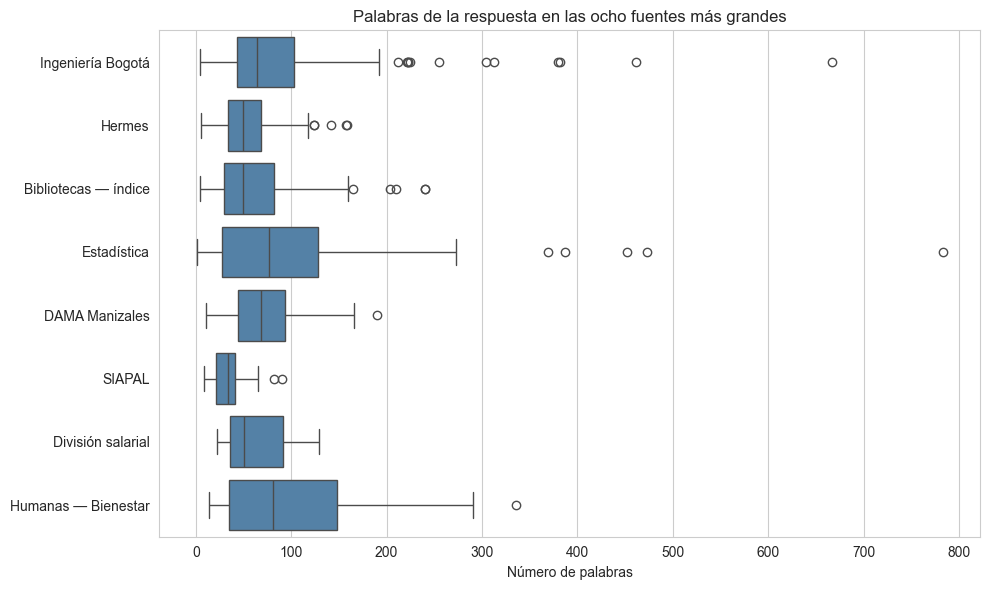

Seis preguntas publicadas en más de una fuente:


,pregunta,fuentes,filas
0,¿Puedo usar comodines al realizar las búsquedas?,SIAPAL | DAMA Manizales,3
1,¿Se puede solicitar la cancelación del periodo...,Ingeniería Bogotá | Estadística,3
2,¿Cuáles son los criterios de financiación para...,Ingeniería Bogotá | Estadística,3
3,¿Qué condiciones deben darse para abrir un cur...,Ingeniería UECP — FAQ | Ingeniería Bogotá,2
4,¿Cuánto tardan en actualizarse las notas una v...,SIAPAL | DAMA Manizales,2
5,¿Qué debo hacer si en mi horario aparece una a...,SIAPAL | DAMA Manizales,2


In [28]:
import re

def _norm(texto):
    return re.sub(r"\s+", " ", str(texto).casefold()).strip()

def _tokens(texto):
    return set(re.findall(r"[a-záéíóúñü0-9]{3,}", str(texto).casefold()))

conteo_fuentes = df["fuente"].value_counts()
top5 = int(conteo_fuentes.head(5).sum())
print(f"Las 5 fuentes más grandes reúnen {top5} pares, el {100 * top5 / len(df):.1f} % del corpus.")

pregunta_norm = df["pregunta"].map(_norm)
repetidas = pregunta_norm.value_counts()
repetidas = repetidas[repetidas > 1]
fuentes_por_pregunta = df.assign(_q=pregunta_norm).groupby("_q")["fuente"].nunique()
cruce = fuentes_por_pregunta[fuentes_por_pregunta > 1]
print(f"Preguntas distintas: {pregunta_norm.nunique()} de {len(df)} filas.")
print(f"Preguntas que se repiten: {len(repetidas)}. Filas en esas preguntas: {int(repetidas.sum())}.")
print(f"La misma pregunta está en fuentes distintas: {len(cruce)} preguntas, {int(pregunta_norm.isin(cruce.index).sum())} filas.")

sin_signo = ~df["pregunta"].astype(str).str.contains(r"[¿?]", regex=True)
print(f"Preguntas sin ¿ ni ?: {int(sin_signo.sum())}.")
print(df.loc[sin_signo, "fuente"].value_counts().head(4))

jaccard = []
for pregunta, respuesta in zip(df["pregunta"], df["respuesta"]):
    tokens_p, tokens_r = _tokens(pregunta), _tokens(respuesta)
    if not tokens_p or not tokens_r:
        jaccard.append(0.0)
    else:
        jaccard.append(len(tokens_p & tokens_r) / len(tokens_p | tokens_r))
jaccard = pd.Series(jaccard, name="jaccard_pregunta_respuesta")
print(jaccard.describe().round(3))
print(f"Pares con solapamiento menor a 0.05: {int((jaccard < 0.05).sum())}.")

df_caja = df.copy()
df_caja["palabras_respuesta"] = df_caja["respuesta"].astype(str).str.split().str.len()
orden = conteo_fuentes.head(8).index.tolist()
print("Mediana de palabras de la respuesta, ocho fuentes más grandes:")
print(df_caja[df_caja["fuente"].isin(orden)].groupby("fuente")["palabras_respuesta"].median().reindex(orden).round(1))

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_caja[df_caja["fuente"].isin(orden)],
    y="fuente",
    x="palabras_respuesta",
    order=orden,
    color="steelblue",
)
plt.title("Palabras de la respuesta en las ocho fuentes más grandes")
plt.xlabel("Número de palabras")
plt.ylabel("")
plt.tight_layout()
plt.show()

ejemplos = (
    df.assign(_q=pregunta_norm)
    .loc[lambda tabla: tabla["_q"].isin(cruce.index)]
    .groupby("_q", sort=False)
    .agg(
        pregunta=("pregunta", "first"),
        fuentes=("fuente", lambda serie: " | ".join(dict.fromkeys(serie))),
        filas=("fuente", "size"),
    )
    .sort_values("filas", ascending=False)
    .head(6)
)
print("Seis preguntas publicadas en más de una fuente:")
display(ejemplos.reset_index(drop=True))


**Explicación.** Las cinco fuentes grandes reúnen **578 pares, el 68.9 %** del corpus. Ingeniería Bogotá, Hermes, Bibliotecas, Estadística y DAMA Manizales pueden dominar un ranking que no mire la fuente.

Hay **785** preguntas distintas en 839 filas. **45** se repiten (99 filas) y **24** están publicadas en dos dependencias (51 filas). La tabla que imprime la celda muestra seis de esas preguntas, con las dos fuentes de cada una. La fase 4 tiene que poder devolver más de un par oficial.

El índice de Jaccard mide las palabras compartidas entre la pregunta y su respuesta. La mediana es **0.064** y **322** pares quedan bajo 0.05. La respuesta no repite la pregunta: por eso comparar la consulta contra el párrafo largo recupera mal, y compararla contra la pregunta del corpus es la vía que sigue.

**27** preguntas no traen `¿` ni `?`. Diez son términos del glosario de la UECP; el resto son encabezados cortos de Bibliotecas y de personal académico. Entran al corpus como pares, y la fase 3 no debe exigir el signo para reconocerlos.

La caja compara la longitud de la respuesta en las ocho fuentes con más pares. El eje llega hasta la respuesta más larga del corpus, 783 palabras. La mediana va de **34** en SIAPAL y **49** en Hermes y en Bibliotecas, hasta **77** en Estadística y **81** en Bienestar. Una sola longitud «típica» de respuesta no describe el corpus.

La tabla muestra seis de esas preguntas. Los comodines en las búsquedas, la actualización de las notas y el horario con una asignatura ajena están en SIAPAL y en DAMA Manizales. La cancelación del periodo académico y la financiación de la movilidad están en Ingeniería Bogotá y en Estadística. Abrir un curso está en la UECP y en Ingeniería Bogotá. No son duplicados para borrar: cada página tiene su propia respuesta.


### **Hallazgos del análisis exploratorio**
---

Lo que queda listo para la fase 3:

- **Tamaño.** 839 pares en español. El DataFrame pesa 0.83 MB y el CSV, 0.55 MB.
- **Desbalance.** Cinco fuentes reúnen 578 pares, el 68.9 % del corpus: Ingeniería Bogotá (161), Hermes (136), Bibliotecas (105), Estadística (102) y DAMA Manizales (74). Entre esas ocho más grandes, la mediana de la respuesta va de 34 palabras (SIAPAL) a 81 (Humanas — Bienestar).
- **Preguntas repetidas.** Hay 785 preguntas distintas en 839 filas. 45 preguntas se repiten y 24 de ellas están en dos fuentes, por ejemplo la inscripción a grados en Ingeniería y en Estadística. La fase 4 puede recuperar dos respuestas oficiales para la misma consulta.
- **Pregunta y respuesta no comparten vocabulario.** La mediana del índice de Jaccard entre los dos textos es 0.064. 322 pares quedan por debajo de 0.05. Por eso la consulta se compara con la pregunta del corpus, no con el párrafo de la respuesta.
- **Longitudes.** La pregunta tiene media 11.7 palabras (74 caracteres). La respuesta tiene media 72.9 palabras y 478 caracteres. Caracteres y palabras miden lo mismo: correlación 0.975 y 0.994. Se deja el conteo en palabras.
- **Calidad.** Pregunta y respuesta están completas. 587 filas no traen sección y 252 sí, en 36 títulos. 27 preguntas no llevan signo de interrogación: 10 son términos del glosario.
- **Limpieza.** Se guardan el texto original, la versión normalizada y la lematizada. En la lematizada se quitan palabras de función y se dejan los verbos, para que una pregunta como «¿qué puedo hacer?» no desaparezca.


In [29]:
# La celda imprime el resumen que queda arriba. No calcula columnas nuevas.
print("Hallazgos del análisis exploratorio:")
print("• Tamaño: 839 pares, español. DataFrame 0.83 MB, CSV 0.55 MB.")
print("• Desbalance: 5 fuentes reúnen 578 pares (68.9 %).")
print("• Preguntas: 785 distintas. 45 se repiten y 24 están en dos fuentes.")
print("• Solapamiento pregunta-respuesta: mediana de Jaccard 0.064. 322 pares por debajo de 0.05.")
print("• Longitudes: pregunta 11.7 palabras y 74 caracteres; respuesta 72.9 palabras y 478 caracteres.")
print("• Caracteres y palabras van juntos (correlación 0.975 y 0.994). Se usa el conteo en palabras.")
print("• Calidad: 587 filas sin sección; 252 con sección. 27 preguntas sin signo de interrogación.")
print("• Limpieza: original, normalizada y lematizada. Los verbos se conservan.")


Hallazgos del análisis exploratorio:
• Tamaño: 839 pares, español. DataFrame 0.83 MB, CSV 0.55 MB.
• Desbalance: 5 fuentes reúnen 578 pares (68.9 %).
• Preguntas: 785 distintas. 45 se repiten y 24 están en dos fuentes.
• Solapamiento pregunta-respuesta: mediana de Jaccard 0.064. 322 pares por debajo de 0.05.
• Longitudes: pregunta 11.7 palabras y 74 caracteres; respuesta 72.9 palabras y 478 caracteres.
• Caracteres y palabras van juntos (correlación 0.975 y 0.994). Se usa el conteo en palabras.
• Calidad: 587 filas sin sección; 252 con sección. 27 preguntas sin signo de interrogación.
• Limpieza: original, normalizada y lematizada. Los verbos se conservan.


**Explicación.** Esta celda no calcula columnas nuevas. Repite el resumen para que la salida y el texto coincidan: 839 pares, 68.9 % en cinco fuentes, 45 preguntas repetidas, mediana de Jaccard 0.064 y la limpieza en tres versiones.


### **Pasos de la limpieza**

```mermaid
flowchart TD
  O["pregunta / respuesta originales"] --> N["1. Normalizar<br/>minúsculas y espacios"]
  N --> G["2. Grafía<br/>comillas, rayas, viñetas"]
  G --> LM["3. Lematizar con spaCy<br/>lote nlp.pipe"]
  LM --> F["4. Quitar DET ADP CCONJ SCONJ PRON PART"]
  F --> K["Conservar verbos y auxiliares"]
  N --> PN["pregunta_normalizada"]
  K --> PL["pregunta_texto_limpio"]
  PN --> EXP["CSV limpio"]
  PL --> EXP
  O --> EXP
```

La normalizada es la que compara la consulta escrita. Los lemas son la segunda configuración. `fuente` no entra al vector.


## **2. Limpieza de los Textos**
---

La selección de las técnicas de preprocesamiento del corpus puede variar en cada conjunto de datos. Recuerde que puede aplicar (no necesariamente todas) las técnicas generales vistas en el curso, tales como:

- Tokenizacion
- Normalización de textos.
- Limpieza con expresiones regulares.
- Lematización.
- Filtrado de palabras.
- Modificaciones en la grafía.

### Dependencia para exportar a Excel (Colab)
Ejecuta la siguiente celda **una vez** para instalar `openpyxl`. Luego ejecuta la celda de limpieza (Sección 2).

In [30]:
# Instalación para Colab: librería necesaria para exportar a Excel (.xlsx)
try:
    import openpyxl
    print("openpyxl ya está instalado.")
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl", "-q"])
    print("openpyxl instalado correctamente.")

openpyxl ya está instalado.


**Explicación.** `openpyxl` escribe el Excel con una hoja por paso de la limpieza. Si ya está instalado, la celda no vuelve a descargarlo.


In [31]:
# =============================================================================
# 2. Limpieza de los Textos — Técnicas elegidas para recuperación de FAQ
# =============================================================================
# 1. Normalización: minúsculas y espacios.
# 2. Grafía: comillas, rayas, viñetas y puntos suspensivos.
# 3. Lematización con spaCy, en lote.
#    Se quitan determinantes, preposiciones, conjunciones y pronombres.
#    Se conservan verbos y auxiliares: en español "hacer" y "poder" vienen
#    marcados como stopword y, si se borran, hay preguntas que quedan vacías.
# El texto original no se pisa. Se exportan la versión normalizada y la lematizada.

FUNCIONES = {"DET", "ADP", "CCONJ", "SCONJ", "PRON", "PART"}


def normalizar_texto(texto):
    """Minúsculas y un solo espacio."""
    if pd.isna(texto) or not isinstance(texto, str):
        return ""
    t = texto.strip().lower()
    return re.sub(r"\s+", " ", t)


def limpiar_con_regex(texto):
    """Unifica la tipografía de las páginas y deja el resto del español."""
    if not texto:
        return ""
    t = texto
    t = re.sub(r"[\u2013\u2014\u2015]", "-", t)
    t = re.sub(r"[\u201c\u201d\u201e\u201f]", '"', t)
    t = re.sub(r"[\u2018\u2019\u201a\u201b]", "'", t)
    t = re.sub(r"\u2026", "...", t)
    t = re.sub(r"[\u2022\u2023\u2043\u2219]", " ", t)
    t = re.sub(r"[^\x00-\x7FáéíóúÁÉÍÓÚñÑüÜ\s\.,;:!?¿\-'\"°/()]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def lematizar_serie(serie):
    """Lematiza en lote. Quita palabras de función y conserva los verbos."""
    textos = serie.fillna("").astype(str).tolist()
    salida = []
    for doc in nlp.pipe(textos, batch_size=64):
        lemas = []
        for token in doc:
            if token.is_space or token.is_punct or token.pos_ in FUNCIONES:
                continue
            lema = token.lemma_.lower().strip()
            if lema:
                lemas.append(lema)
        salida.append(" ".join(lemas))
    return pd.Series(salida, index=serie.index)


columnas_texto = ["pregunta", "respuesta", "titulo_seccion"]

print("=" * 70)
print("PASO 0 — Ejemplos de basura detectados (antes de limpiar)")
print("=" * 70)
df_ejemplos_basura = traer_ejemplos_basura(df_analisis_ruido, ["respuesta", "pregunta", "titulo_seccion"])
display(df_ejemplos_basura.head(8))
print()

print("=" * 70)
print("PASO 1 — Corpus ORIGINAL (muestra de 3 filas)")
print("=" * 70)
display(df[columnas_texto].head(3))
print()

print("=" * 70)
print("PASO 2 — Después de NORMALIZACIÓN (minúsculas, espacios unificados)")
print("=" * 70)
df_paso2 = df.copy()
for col in columnas_texto:
    df_paso2[col] = df_paso2[col].astype(str).map(normalizar_texto)
display(df_paso2[columnas_texto].head(3))
print()

print("=" * 70)
print("PASO 3 — Después de NORMALIZACIÓN + REGEX (guiones, comillas, viñetas)")
print("=" * 70)
df_norm = df.copy()
for col in columnas_texto:
    df_norm[col] = df_norm[col].astype(str).map(normalizar_texto).map(limpiar_con_regex)
display(df_norm[columnas_texto].head(3))
print()

print("=" * 70)
print("PASO 4 — Lematización. Se quitan palabras de función y se dejan los verbos")
print("=" * 70)
df_limpio = df.copy()
df_limpio["pregunta_normalizada"] = df_norm["pregunta"]
df_limpio["respuesta_normalizada"] = df_norm["respuesta"]
df_limpio["pregunta_texto_limpio"] = lematizar_serie(df_norm["pregunta"])
df_limpio["respuesta_texto_limpio"] = lematizar_serie(df_norm["respuesta"])
columnas_ver = ["pregunta", "pregunta_normalizada", "pregunta_texto_limpio", "respuesta_texto_limpio"]
display(df_limpio[columnas_ver].head(5))

palabras = df_limpio["pregunta"].astype(str).str.split().str.len()
lemas = df_limpio["pregunta_texto_limpio"].str.split().str.len()
print(f"Palabras en la pregunta original: media {palabras.mean():.1f}.")
print(f"Lemas útiles en la pregunta: media {lemas.mean():.1f}.")
print(f"Preguntas que quedan sin lemas: {int((lemas == 0).sum())}.")
print(f"Preguntas que quedan con 1 o 2 lemas: {int((lemas <= 2).sum())}.")
print()

print("=" * 70)
print("PASO 5 — Validación: análisis de ruido DESPUÉS de la normalización")
print("=" * 70)
df_para_ruido = pd.DataFrame({
    "pregunta": df_limpio["pregunta_normalizada"],
    "respuesta": df_limpio["respuesta_normalizada"],
    "titulo_seccion": df_norm["titulo_seccion"],
})
df_ruido_despues = aplicar_analisis_ruido(df_para_ruido, columnas_texto)
columnas_error = [c for c in df_ruido_despues.columns if "mal_codificados" in c]
total_errores_despues = df_ruido_despues[columnas_error].sum().sum()
print(f"Caracteres fuera del español básico, después de la limpieza: {int(total_errores_despues)}.")
print("Esos dos son el signo de ordinal °, como en 2°. Se conserva: indica un orden y no es un carácter mal codificado.")
display(df_ruido_despues[columnas_error].sum().to_frame("total"))
print()

print("=" * 70)
print("PASO 6 — DataFrame final listo para exportar")
print("=" * 70)
columnas_exportar = [
    "pregunta", "respuesta", "fuente", "url", "titulo_seccion",
    "pregunta_normalizada", "respuesta_normalizada",
    "pregunta_texto_limpio", "respuesta_texto_limpio",
]
df_export = df_limpio[columnas_exportar].copy()
ruta_export = "corpus_faq_unal_fase2_limpio.csv"
df_export.to_csv(ruta_export, index=False, encoding="utf-8")
print(f"Columnas exportadas: {list(df_export.columns)}")
print(f"Filas: {len(df_export)}")
print(f"Archivo CSV guardado: {ruta_export}")
display(df_export[columnas_ver].head(3))

print()
print("=" * 70)
print("EXCEL — Guardando cada dataframe en una hoja")
print("=" * 70)
ruta_excel = "corpus_faq_unal_fase2_limpieza.xlsx"
with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:
    df_ejemplos_basura.to_excel(writer, sheet_name="0_Ejemplos_basura", index=True)
    df[columnas_texto].to_excel(writer, sheet_name="1_Corpus_original", index=True)
    df_paso2[columnas_texto].to_excel(writer, sheet_name="2_Paso_normalizacion", index=True)
    df_norm[columnas_texto].to_excel(writer, sheet_name="3_Paso_regex", index=True)
    df_export.to_excel(writer, sheet_name="6_Export_final", index=True)
print(f"Excel guardado: {ruta_excel}")
print("Hojas: 0_Ejemplos_basura | 1_Corpus_original | 2_Paso_normalizacion | 3_Paso_regex | 6_Export_final")


PASO 0 — Ejemplos de basura detectados (antes de limpiar)


,respuesta_ejemplos_basura,pregunta_ejemplos_basura,titulo_seccion_ejemplos_basura
244,"[“, ”]",NaN,NaN
299,"[1.ª., 2.ª, 3.ª., 4.ª, 5.ª]",NaN,NaN
318,"[“, ”]",NaN,NaN
319,"[“, ”]",NaN,NaN
360,"[2º, 3º.]",NaN,NaN
364,[–],NaN,NaN
373,"[“, ”, “, ”, “, ”, “, ”]",NaN,NaN
396,"[1º, 2º, 3º.]",NaN,NaN



PASO 1 — Corpus ORIGINAL (muestra de 3 filas)


,pregunta,respuesta,titulo_seccion
0,Recibí un correo para la aceptación del acta d...,Debe realizar la aceptación del acta de inicio...,
1,¿Cómo puedo conocer la calificación del proyec...,El docente investigador principal debe ingresa...,
2,¿Cómo puedo saber cuáles fueron los requisitos...,El docente investigador principal debe ingresa...,



PASO 2 — Después de NORMALIZACIÓN (minúsculas, espacios unificados)


,pregunta,respuesta,titulo_seccion
0,recibí un correo para la aceptación del acta d...,debe realizar la aceptación del acta de inicio...,
1,¿cómo puedo conocer la calificación del proyec...,el docente investigador principal debe ingresa...,
2,¿cómo puedo saber cuáles fueron los requisitos...,el docente investigador principal debe ingresa...,


... (7 outputs left out)


PASO 6 — DataFrame final listo para exportar
Columnas exportadas: ['pregunta', 'respuesta', 'fuente', 'url', 'titulo_seccion', 'pregunta_normalizada', 'respuesta_normalizada', 'pregunta_texto_limpio', 'respuesta_texto_limpio']
Filas: 839
Archivo CSV guardado: corpus_faq_unal_fase2_limpio.csv


,pregunta,pregunta_normalizada,pregunta_texto_limpio,respuesta_texto_limpio
0,Recibí un correo para la aceptación del acta d...,recibí un correo para la aceptación del acta d...,recibir correo aceptación acta inicio deber hacer,deber realizar aceptación acta inicio ingresar...
1,¿Cómo puedo conocer la calificación del proyec...,¿cómo puedo conocer la calificación del proyec...,poder conocer calificación proyecto postular,docente investigador principal deber ingresar ...
2,¿Cómo puedo saber cuáles fueron los requisitos...,¿cómo puedo saber cuáles fueron los requisitos...,poder saber ser requisito no cumplir proyecto ...,docente investigador principal deber ingresar ...



EXCEL — Guardando cada dataframe en una hoja


Excel guardado: corpus_faq_unal_fase2_limpieza.xlsx
Hojas: 0_Ejemplos_basura | 1_Corpus_original | 2_Paso_normalizacion | 3_Paso_regex | 6_Export_final


**Explicación.** La limpieza no pisa el texto de la Fase 1. Cada fila sale con tres versiones de la pregunta y de la respuesta.

1. **Paso 0.** Muestra los caracteres que el detector marcó: comillas curvas, ordinales y viñetas.
2. **Paso 1.** Muestra la pregunta y la respuesta tal como quedaron en la Fase 1.
3. **Paso 2.** Pasa el texto a minúsculas y deja un solo espacio entre palabras.
4. **Paso 3.** Unifica comillas, rayas, puntos suspensivos y viñetas. El signo `°` se conserva.
5. **Paso 4.** spaCy lematiza en lote, no fila por fila. Quita determinantes, preposiciones, conjunciones y pronombres, y **deja los verbos**. Con la regla anterior, *hacer* y *poder* se borraban y 9 preguntas quedaban vacías, entre ellas «¿qué puedo hacer?». Con esta regla ninguna pregunta queda vacía: la media baja de 11.7 palabras a **6.5 lemas**, y 39 preguntas quedan en uno o dos lemas porque ya eran cortas («cancelar movilidad»).
6. **Paso 5.** Sobre el texto normalizado siguen **2** signos `°`.
7. **Paso 6.** Guarda las 839 filas en `corpus_faq_unal_fase2_limpio.csv`. `pregunta` y `respuesta` son el original. `pregunta_normalizada` sirve para comparar la consulta escrita. `pregunta_texto_limpio` es la versión de lemas para la fase 3. El Excel guarda cada paso en una hoja.

`fuente`, `url` y `titulo_seccion` no se lematizan.


### **2.1. Comprobación de la limpieza**

La consulta de prueba no es la pregunta completa. Se le quitan las palabras de función y, si quedan más de tres palabras de contenido, se elimina la última. Así se parece más a alguien que escribe una versión corta de la FAQ.

Con esa consulta se arma un TF-IDF y se mide si el par correcto queda de primero (Recall@1), entre los cinco primeros (Recall@5) y en qué puesto medio (MRR). Se comparan la pregunta y la respuesta, en superficie y en lemas. También se prueba pegar el título de sección a la pregunta, y el techo de copiar la pregunta tal cual.

Esto no es el modelo de la fase 4. Es la medida que dice qué columna vale la pena representar.


In [32]:
import re
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PALABRAS_FUNCION = {
    "que", "qué", "como", "cómo", "cual", "cuál", "cuales", "cuáles",
    "donde", "dónde", "cuando", "cuándo", "quien", "quién", "quienes", "quiénes",
    "cuanto", "cuánto", "cuanta", "cuánta", "cuantos", "cuántos",
    "para", "por", "del", "de", "la", "el", "los", "las", "un", "una",
    "es", "son", "se", "me", "mi", "con", "en", "al", "lo", "hay", "y", "o", "a",
    "su", "sus", "le", "les", "te", "nos", "esto", "esta", "este",
}

def consulta_corta(texto):
    tokens = re.findall(r"[a-záéíóúñü0-9]+", str(texto).casefold())
    utiles = [token for token in tokens if token not in PALABRAS_FUNCION and len(token) > 2]
    if len(utiles) > 3:
        utiles = utiles[:-1]
    return " ".join(utiles)

def recuperar(consultas, documentos, ngramas):
    vectorizador = TfidfVectorizer(min_df=1, ngram_range=(1, ngramas))
    matriz = vectorizador.fit_transform(documentos)
    similitud = cosine_similarity(vectorizador.transform(consultas), matriz)
    orden = np.argsort(-similitud, axis=1)
    indice = np.arange(len(consultas))
    recall_1 = float((orden[:, 0] == indice).mean())
    recall_5 = float(np.any(orden[:, :5] == indice[:, None], axis=1).mean())
    recíproco = [1.0 / (int(np.where(orden[i] == i)[0][0]) + 1) for i in indice]
    return recall_1, recall_5, float(np.mean(recíproco))

corpus = df_export.fillna("")
consulta_superficie = corpus["pregunta_normalizada"].map(consulta_corta)
consulta_lemas = corpus["pregunta_texto_limpio"].map(consulta_corta)
print(f"Consultas vacías: superficie {int(consulta_superficie.eq('').sum())}, lemas {int(consulta_lemas.eq('').sum())}.")
print(f"Palabras en la consulta corta: media {consulta_superficie.str.split().str.len().mean():.2f}.")

pruebas = [
    ("superficie -> pregunta", consulta_superficie, corpus["pregunta_normalizada"]),
    ("superficie -> respuesta", consulta_superficie, corpus["respuesta_normalizada"]),
    ("lemas -> pregunta", consulta_lemas, corpus["pregunta_texto_limpio"]),
    ("lemas -> respuesta", consulta_lemas, corpus["respuesta_texto_limpio"]),
    ("superficie -> pregunta + sección", consulta_superficie, (corpus["pregunta_normalizada"] + " " + corpus["titulo_seccion"]).str.strip()),
    ("copia exacta -> pregunta", corpus["pregunta_normalizada"], corpus["pregunta_normalizada"]),
]
filas = []
for ngramas in (1, 2):
    for nombre, consultas, documentos in pruebas:
        recall_1, recall_5, mrr = recuperar(consultas.tolist(), documentos.tolist(), ngramas)
        filas.append({
            "ngramas": ngramas,
            "comparación": nombre,
            "Recall@1": round(recall_1, 3),
            "Recall@5": round(recall_5, 3),
            "MRR": round(mrr, 3),
        })
tabla = pd.DataFrame(filas)
display(tabla)


Consultas vacías: superficie 0, lemas 0.
Palabras en la consulta corta: media 5.35.


,ngramas,comparación,Recall@1,Recall@5,MRR
0,1,superficie -> pregunta,0.912,0.998,0.953
1,1,superficie -> respuesta,0.242,0.474,0.351
2,1,lemas -> pregunta,0.901,0.996,0.947
3,1,lemas -> respuesta,0.268,0.505,0.379
4,1,superficie -> pregunta + sección,0.905,0.998,0.948
5,1,copia exacta -> pregunta,0.931,0.998,0.963
6,2,superficie -> pregunta,0.902,0.998,0.947
7,2,superficie -> respuesta,0.232,0.456,0.338
8,2,lemas -> pregunta,0.906,0.998,0.950
9,2,lemas -> respuesta,0.273,0.515,0.385


**Explicación.** La consulta corta no queda vacía en ningún par y tiene una media de 5.35 palabras. La tabla usa esas 839 consultas.

Con palabras sueltas, comparar contra la **pregunta normalizada** deja el par correcto de primero en el **91.2 %** de los casos (Recall@5 **0.998**, MRR **0.953**). Comparar contra la **respuesta** baja el Recall@1 a **0.242**. Los lemas de la respuesta suben ese número solo hasta **0.268**. El campo pesa mucho más que la lematización.

Entre pregunta normalizada y pregunta lematizada la diferencia es de un punto, y cambia de lado si se usan bigramas: **0.912** contra **0.901** con palabras sueltas, y **0.902** contra **0.906** con bigramas. La fase 3 representa primero la pregunta normalizada con palabras sueltas. Los lemas quedan como segunda configuración.

Pegar el título de sección a la pregunta deja el Recall@1 en **0.905**. El título se conserva como dato de la fila y no se mezcla con el texto que se compara.

El techo, copiar la pregunta oficial tal cual, es **0.931** y no 1. Hay 99 filas que comparten la pregunta normalizada con otra: el vector empata y una sola copia puede quedar de primera. Por eso la fase 4 tiene que poder mostrar más de un par cuando la misma pregunta está publicada en dos dependencias.


### **Qué sale hacia la Fase 3**

```mermaid
flowchart LR
  subgraph Guarda["Se guarda"]
    PN["pregunta_normalizada"]
    PL["pregunta_texto_limpio"]
    META["fuente · url · titulo_seccion"]
  end
  subgraph No["No se usa como único campo de búsqueda"]
    R["respuesta"]
  end
  PN --> F3["Fase 3: vectorizar primero la normalizada"]
  PL --> F3
  META --> F3
```


### **2.2. Qué se lleva a la fase 3**

- Representar primero `pregunta_normalizada`.
- Guardar `pregunta_texto_limpio` para compararla, no para sustituir a la anterior.
- No usar la respuesta como único texto de la búsqueda.
- Dejar `fuente`, `url` y `titulo_seccion` fuera del vector y disponibles para filtrar o para mostrar la procedencia.
- Preparar la evaluación para el empate entre preguntas repetidas: Recall@1 de una copia exacta ya se queda en 0.931.


## **Créditos**

* **Profesor:** [Felipe Restrepo Calle](https://dis.unal.edu.co/~ferestrepoca/)
* **Asistentes docentes:**
    - [Juan Sebastián Lara Ramírez](https://www.linkedin.com/in/juan-sebastian-lara-ramirez-43570a214/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](mailto:rsuperlano@unal.edu.co).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*